### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'usdprice']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,0.563348
2009-01-01,0.452433
2010-01-01,0.505708
2011-01-01,0.546463
2012-01-01,0.467904


#### 2. Exchange Rate Dataset

In [8]:
exchange = get_dataset('\\Datasets\\exchange_rate_US.csv')
exchange.head()

,Date,MMK Rate
0,15-Feb-22,"1,778.00"
1,14-Feb-22,"1,778.00"
2,11-Feb-22,"1,778.00"
3,10-Feb-22,"1,778.00"
4,9-Feb-22,"1,778.00"


In [9]:
exchange.columns = ['date', 'exchange_rate']
exchange['date'] = pd.to_datetime(exchange['date'])
exchange = exchange.sort_values(by='date') 
exchange.head()

,date,exchange_rate
2345,2012-07-02,878
2344,2012-07-03,880
2343,2012-07-04,881
2342,2012-07-05,883
2341,2012-07-06,883


##### Filling data with linear interpolation

In [10]:
exchange = exchange.interpolate(method='linear')
exchange

,date,exchange_rate
2345,2012-07-02,878
2344,2012-07-03,880
2343,2012-07-04,881
2342,2012-07-05,883
2341,2012-07-06,883
...,...,...
4,2022-02-09,"1,778.00"
3,2022-02-10,"1,778.00"
2,2022-02-11,"1,778.00"
1,2022-02-14,"1,778.00"


In [11]:
exchange = exchange.set_index('date')
exchange.head()

,exchange_rate
date,
2012-07-02,878
2012-07-03,880
2012-07-04,881
2012-07-05,883
2012-07-06,883


In [12]:
exchange['exchange_rate'] = pd.to_numeric([x.replace(',', '') for x in exchange['exchange_rate']])
exchange

,exchange_rate
date,
2012-07-02,878.0
2012-07-03,880.0
2012-07-04,881.0
2012-07-05,883.0
2012-07-06,883.0
...,...
2022-02-09,1778.0
2022-02-10,1778.0
2022-02-11,1778.0


In [13]:
exchange = exchange.resample('AS').mean()
exchange.head()

,exchange_rate
date,
2012-01-01,862.814516
2013-01-01,935.270492
2014-01-01,980.246964
2015-01-01,1169.244186
2016-01-01,1232.335907


### Merge Exchange Rate and Food Price

In [14]:
food_price_exchange = food_price.join(exchange, how='inner')
food_price_exchange

,food_price,exchange_rate
date,,
2012-01-01,0.467904,862.814516
2013-01-01,0.513739,935.270492
2014-01-01,0.918071,980.246964
2015-01-01,1.059368,1169.244186
2016-01-01,1.182692,1232.335907
2017-01-01,1.206721,1360.344262
2018-01-01,1.234046,1428.599174
2019-01-01,1.253202,1522.560759
2020-01-01,0.675675,1377.515812


### Correlation

In [15]:
correlation=food_price_exchange['food_price'].corr(food_price_exchange['exchange_rate'])
correlation

0.48561469529202844

### Make scatter plot

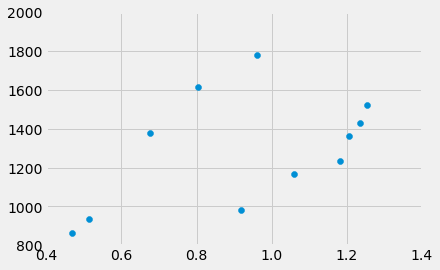

In [16]:
plt.scatter(food_price_exchange['food_price'],food_price_exchange['exchange_rate'])
plt.show()

### Normalization

In [17]:
date = food_price_exchange.index

In [18]:
scaler = MinMaxScaler()

In [19]:
food_price_exchange = scaler.fit_transform(food_price_exchange)
food_price_exchange = pd.DataFrame(food_price_exchange)
food_price_exchange['date'] = date
food_price_exchange.set_index('date', inplace=True)
food_price_exchange.columns = ['food_price', 'exchange_rate']
food_price_exchange.head()

,food_price,exchange_rate
date,,
2012-01-01,0.000000,0.000000
2013-01-01,0.058367,0.079171
2014-01-01,0.573243,0.128315
2015-01-01,0.753172,0.334828
2016-01-01,0.910212,0.403767


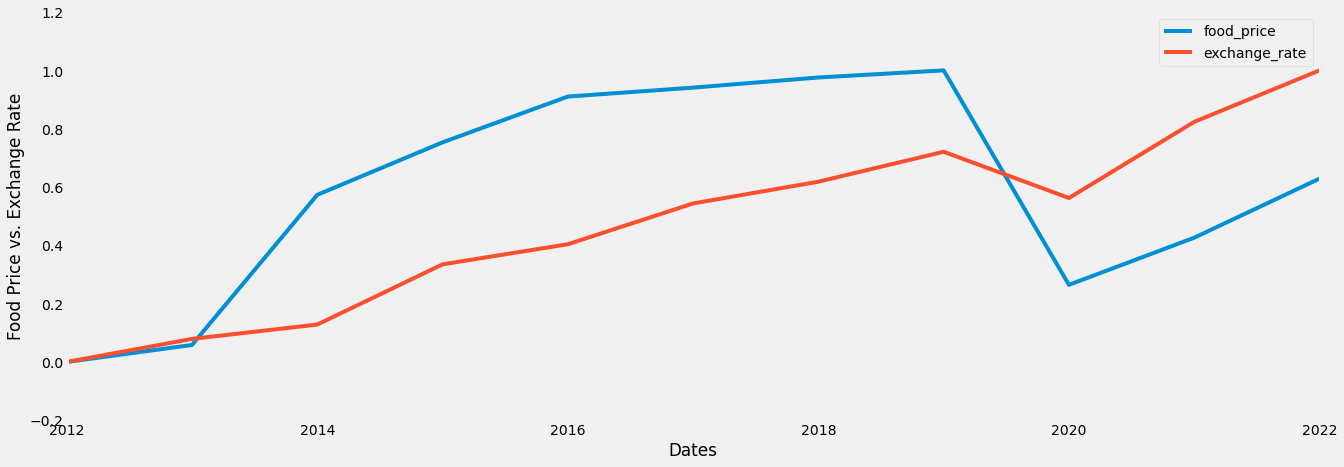

In [20]:
line_ax = food_price_exchange.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Exchange Rate')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is positive relation between Food Price and Exchange Rate</span>